<a href="https://colab.research.google.com/github/Athenessa/bangkok-flood-data-analytics/blob/main/Part4_Data_Analysis_and_Insights.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [7]:
file_path = "/content/drive/MyDrive/study/Junior/Data_sci/Project/flooding_cleaned.xlsx"
df = pd.read_excel(file_path, sheet_name= "flood")

In [8]:
df.head()

,id,date,month,season,year,district,location_raw,location_raw_clean,location,location_clean,road,depth_min_cm,depth_max_cm,flood_length_m,traffic_impact,traffic_impact_no_null,start_time_text,start_time,start_time_hr,end_time_text,end_time,duration_min,duration_check,duration_over_3h,rain_mm,dup_key,dup_count
0,1,2024-03-20,3,Dry,2024,พระนคร,ถนนมหาราช วัดโพธิ์,ถนนมหาราช วัดโพธิ์,ถนนมหาราช วัดโพธิ์,ถนนมหาราช วัดโพธิ์,ถนนมหาราช,10.00,15.00,300.00,เต็มผิว,เต็มผิว,8:15 น.,08:15:00,8,8:50 น.,08:50:00,35,True,No,50.50,2024-03-20|พระนคร|ถนนมหาราช วัดโพธิ์|8:15 น.,1
1,2,2024-03-20,3,Dry,2024,ป้อมปราบศัตรูพ่าย,ถนนเสือป่า แยกวรจักร,ถนนเสือป่า แยกวรจักร,ถนนเสือป่า แยกวรจักร,ถนนเสือป่า แยกวรจักร,ถนนเสือป่า,NaN,NaN,NaN,NaN,ไม่ระบุ,8:15 น.,08:15:00,8,8:50 น.,08:50:00,35,True,No,50.50,2024-03-20|ป้อมปราบศัตรูพ่าย|ถนนเสือป่า แยกวรจ...,1
2,3,2024-03-20,3,Dry,2024,หลักสี่,ถนนแจ้งวัฒนะ ช่วงแจ้งวัฒนะซอย10,ถนนแจ้งวัฒนะซ.แจ้งวัฒนะ10,ถนนแจ้งวัฒนะซ.แจ้งวัฒนะ10,ถนนแจ้งวัฒนะซ.แจ้งวัฒนะ10,ถนนแจ้งวัฒนะ,10.00,15.00,100.00,1-2 เลน,1-2 เลน,9:00 น.,09:00:00,9,9:45 น.,09:45:00,45,True,No,50.00,2024-03-20|หลักสี่|ถนนแจ้งวัฒนะซ.แจ้งวัฒนะ10|9...,1
3,4,2024-03-20,3,Dry,2024,ดินแดง,ถนนประชาสงเคราะห์ ช่วงตลาดเช้า,ถนนประชาสงเคราะห์,ถนนประชาสงเคราะห์,ถนนประชาสงเคราะห์,ถนนประชาสงเคราะห์,10.00,15.00,NaN,NaN,ไม่ระบุ,8:10 น.,08:10:00,8,8:55 น.,08:55:00,45,True,No,52.50,2024-03-20|ดินแดง|ถนนประชาสงเคราะห์|8:10 น.,1
4,5,2024-03-20,3,Dry,2024,บางแค,ถนนเพชรเกษม หน้าวัดประดู่,ถนนเพชรเกษม หน้าวัดประดู่,ถนนเพชรเกษม หน้าวัดประดู่,ถนนเพชรเกษม หน้าวัดประดู่,ถนนเพชรเกษม,10.00,15.00,100.00,เต็มผิว,เต็มผิว,8:30 น.,08:30:00,8,9:25 น.,09:25:00,55,True,No,90.50,2024-03-20|บางแค|ถนนเพชรเกษม หน้าวัดประดู่|8:3...,1


In [9]:
df.shape

(841, 27)

In [10]:
df['date'] = pd.to_datetime(df['date'])

print("Start date:", df['date'].min())
print("End date:", df['date'].max())

print("\nRecords by year:")
print(df['year'].value_counts().sort_index())

print("\nUnique observation dates:")
print(df.groupby('year')['date'].nunique())

print("\nRecords by season:")
print(df['season'].value_counts())

Start date: 2024-03-20 00:00:00
End date: 2025-12-05 00:00:00

Records by year:
year
2024    213
2025    628
Name: count, dtype: int64

Unique observation dates:
year
2024    43
2025    70
Name: date, dtype: int64

Records by season:
season
Rainy    685
Dry      156
Name: count, dtype: int64


# **Which months have the highest number of recorded flooding events?**

In [26]:
monthly_events = (
    df.groupby('month')
    .size()
    .reset_index(name='flood_events')
)

monthly_events = monthly_events.sort_values('month')

monthly_events

,month,flood_events
0,2,3
1,3,10
2,4,13
3,5,217
4,6,49
5,7,35
6,8,56
7,9,171
8,10,157
9,11,129


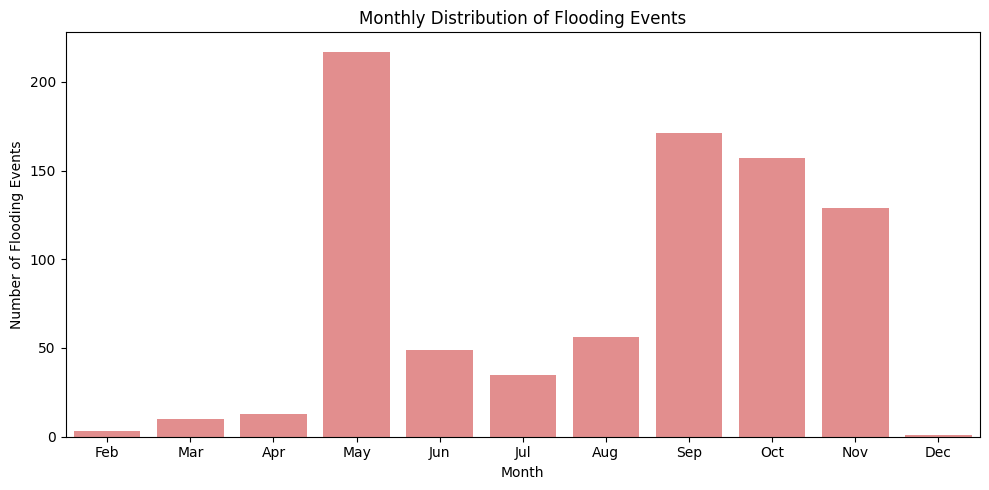

In [27]:
plt.figure(figsize=(10, 5))

sns.barplot(
    data=monthly_events,
    x='month',
    y='flood_events',
    color = "lightcoral"
)

plt.title('Monthly Distribution of Flooding Events')
plt.xlabel('Month')
plt.ylabel('Number of Flooding Events')
plt.xticks(range(11), [
    'Feb', 'Mar', 'Apr', 'May', 'Jun',
    'Jul', 'Aug', 'Sep', 'Oct', 'Nov', 'Dec'
])

plt.tight_layout()
plt.show()

This pattern suggests that the temporal distribution of recorded flooding events may be associated with seasonal rainfall patterns in Bangkok.

However, we need to investigate rainfall data before making that connection confidently.

Also, monthly totals combine both years, so we need to examine each year separately before interpreting this as a recurring seasonal pattern.

**I want to take our analysis one level deeper eiei. 😸**

Counting events tells us how frequently flooding is recorded, but it doesn't tell us how severe or persistent those events are.

**Therefore, our next investigation will be...**

## **How does flooding duration vary across months?**

In [28]:
monthly_duration = (
    df.groupby('month')
    .agg(
        flood_events=('id', 'count'),
        mean_duration=('duration_min', 'mean'),
        median_duration=('duration_min', 'median'),
        max_duration=('duration_min', 'max'),
        over_3h=('duration_over_3h',
                 lambda x: (x == 'Yes').sum())
    )
    .reset_index()
)

monthly_duration['over_3h_pct'] = (
    monthly_duration['over_3h']
    / monthly_duration['flood_events'] * 100
)

print(monthly_duration.round(2))

    month  flood_events  mean_duration  median_duration  max_duration  \
0       2             3          40.00            30.00            65   
1       3            10          62.50            57.50           135   
2       4            13          51.54            40.00           105   
3       5           217         150.07           100.00           830   
4       6            49         120.41           100.00           420   
5       7            35         119.20            55.00           900   
6       8            56          89.80            55.00           390   
7       9           171         167.40           105.00           955   
8      10           157         113.25            80.00           705   
9      11           129         149.29           110.00           690   
10     12             1          40.00            40.00            40   

    over_3h  over_3h_pct  
0         0         0.00  
1         0         0.00  
2         0         0.00  
3        55    

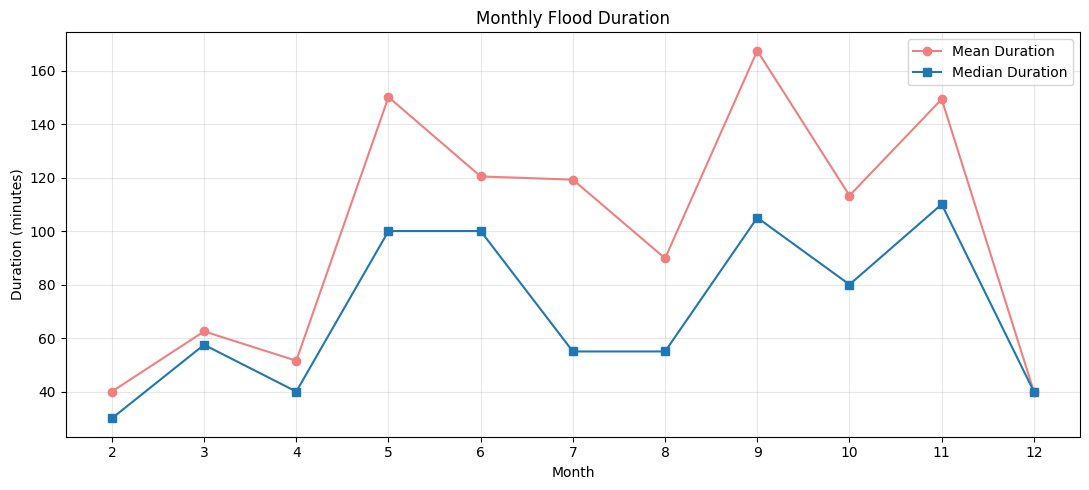

In [29]:
from matplotlib import colormaps
plt.figure(figsize=(11, 5))

plt.plot(
    monthly_duration['month'],
    monthly_duration['mean_duration'],
    marker='o',
    label='Mean Duration',
    color = "lightcoral"
)

plt.plot(
    monthly_duration['month'],
    monthly_duration['median_duration'],
    marker='s',
    label='Median Duration'
)

plt.title('Monthly Flood Duration')
plt.xlabel('Month')
plt.ylabel('Duration (minutes)')

plt.xticks(range(2, 13))
plt.legend()
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()

## **Does flooding differ between rainy and dry seasons?**

In [30]:
seasonal_analysis = (
    df.groupby('season')
    .agg(
        flood_events=('id', 'count'),
        mean_duration=('duration_min', 'mean'),
        median_duration=('duration_min', 'median'),
        over_3h=('duration_over_3h',
                 lambda x: (x == 'Yes').sum())
    )
    .reset_index()
)

seasonal_analysis['over_3h_pct'] = (
    seasonal_analysis['over_3h']
    / seasonal_analysis['flood_events'] * 100
)

print(seasonal_analysis.round(2))

  season  flood_events  mean_duration  median_duration  over_3h  over_3h_pct
0    Dry           156         132.78            90.00       34        21.79
1  Rainy           685         137.33            85.00      146        21.31


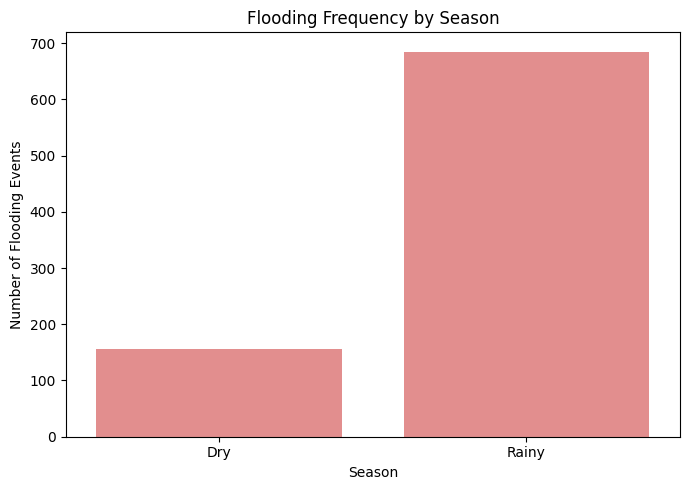

In [32]:
plt.figure(figsize=(7, 5))

sns.barplot(
    data=seasonal_analysis,
    x='season',
    y='flood_events',
    color = "lightcoral"
)

plt.title('Flooding Frequency by Season')
plt.xlabel('Season')
plt.ylabel('Number of Flooding Events')

plt.tight_layout()
plt.show()

## **Are the flooding patterns consistent between 2024 and 2025?**

In [33]:
yearly_monthly = (
    df.groupby(['year', 'month'])
    .size()
    .reset_index(name='flood_events')
)

monthly_comparison = yearly_monthly.pivot(
    index='month',
    columns='year',
    values='flood_events'
).fillna(0)

print(monthly_comparison)

year   2024   2025
month             
2      0.00   3.00
3     10.00   0.00
4      0.00  13.00
5     36.00 181.00
6     15.00  34.00
7     14.00  21.00
8     42.00  14.00
9     21.00 150.00
10    64.00  93.00
11    11.00 118.00
12     0.00   1.00


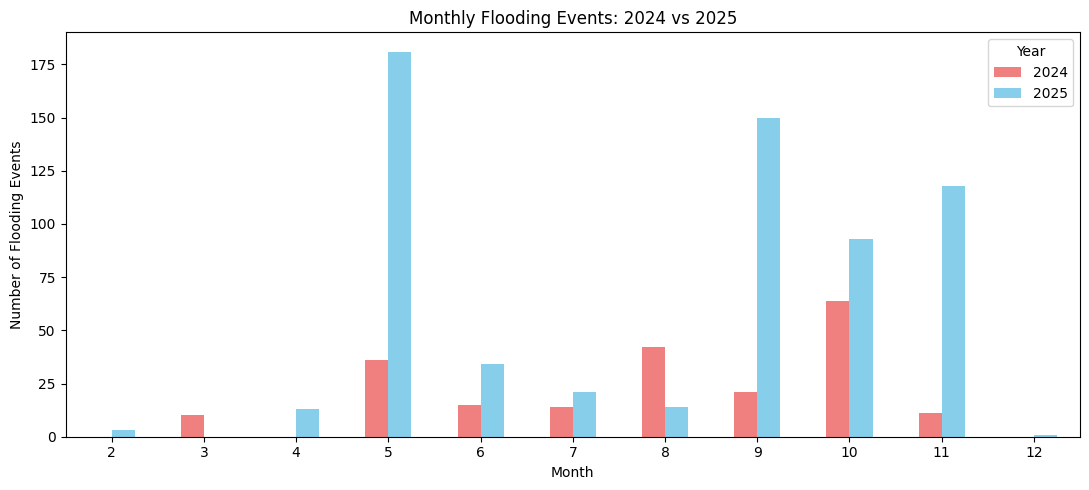

In [37]:
monthly_comparison.plot(
    kind='bar',
    figsize=(11, 5),
    color=['lightcoral', 'skyblue']
)

plt.title('Monthly Flooding Events: 2024 vs 2025')
plt.xlabel('Month')
plt.ylabel('Number of Flooding Events')

plt.legend(title='Year')
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()